# ==============================================================================
# ARCHIVO: Codigos_prueba.ipynb
# DESCRIPCIÓN:
#   Cuaderno de post-procesamiento y filtrado de resultados Post-Layout (PEX)
#   del regulador LDO en tecnología Sky130A.
#   1. Carga los diccionarios guardados en 'resultados_simulacion/graficas_ldo_pex.pkl'
#      y 'resultados_simulacion/parametros_ldo_pex.pkl'.
#   2. Filtra automáticamente las esquinas PVT que no convergieron al punto de
#      operación real y arrojaron voltajes negativos (Vo < 0 V), como
#      'V_1_62_T_-40_sf' y 'V_1_62_T_27_fs'.
#   3. Genera, muestra en pantalla y guarda en alta resolución (300 DPI) las
#      4 gráficas PEX limpias: PSRR, Respuesta Transitoria, Regulación de Línea
#      y Regulación de Carga.
#   4. Recalcula y exporta las tablas CSV de resumen excluyendo los casos
#      no convergidos para obtener estadísticas (mínimo, máximo y promedio) reales.
# ==============================================================================

✅ Total de esquinas PVT cargadas desde 'resultados_simulacion/graficas_ldo_pex.pkl': 81
⚠️ Omitiendo corner por voltaje negativo (t_vo min = -0.9953 V): V_1_62_T_-40_sf
⚠️ Omitiendo corner por voltaje negativo (load_vo min = -0.9953 V): V_1_62_T_-40_sf
📊 Esquinas válidas a graficar tras el filtrado: 80 de 81



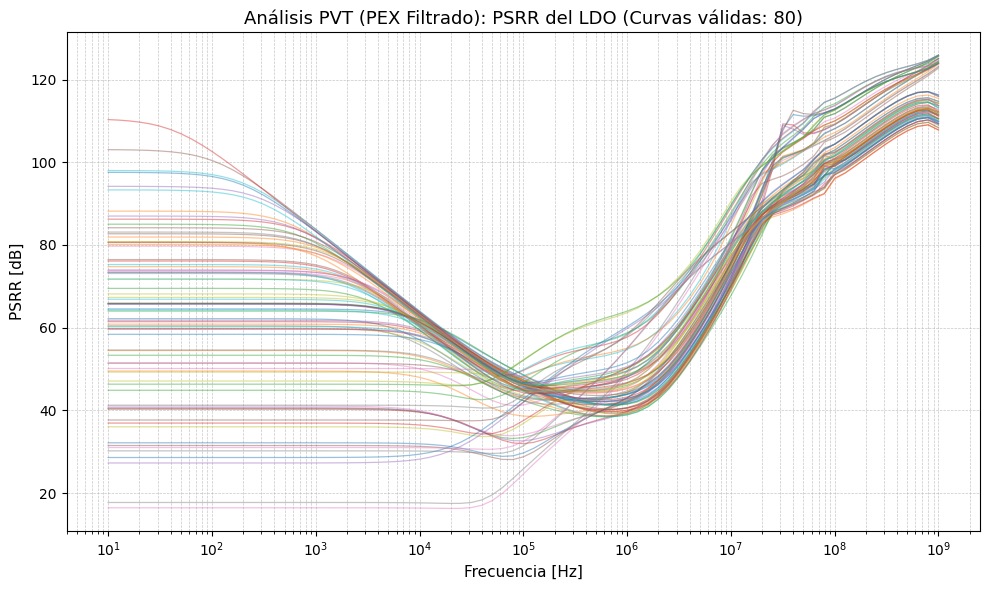

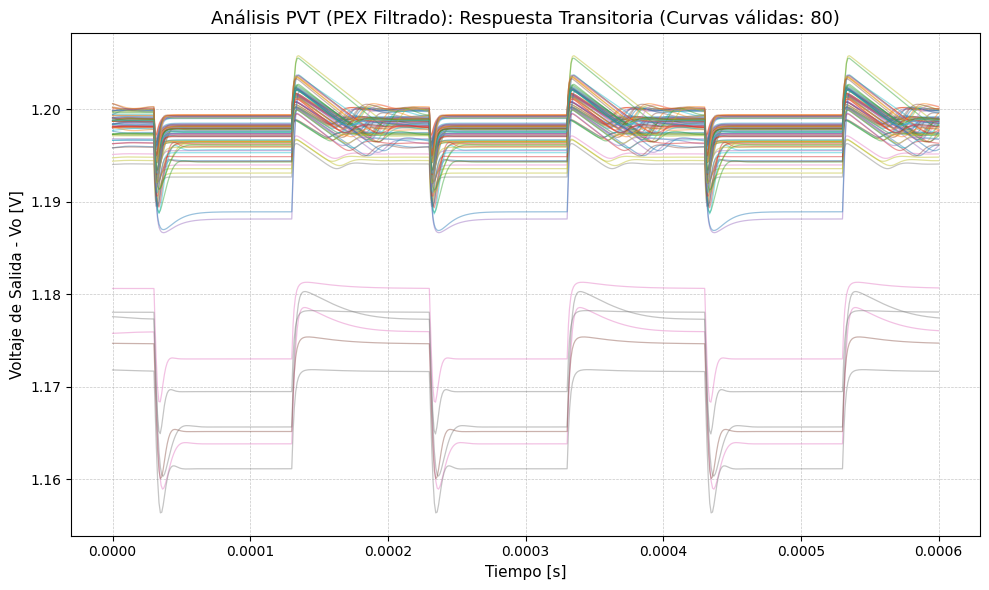

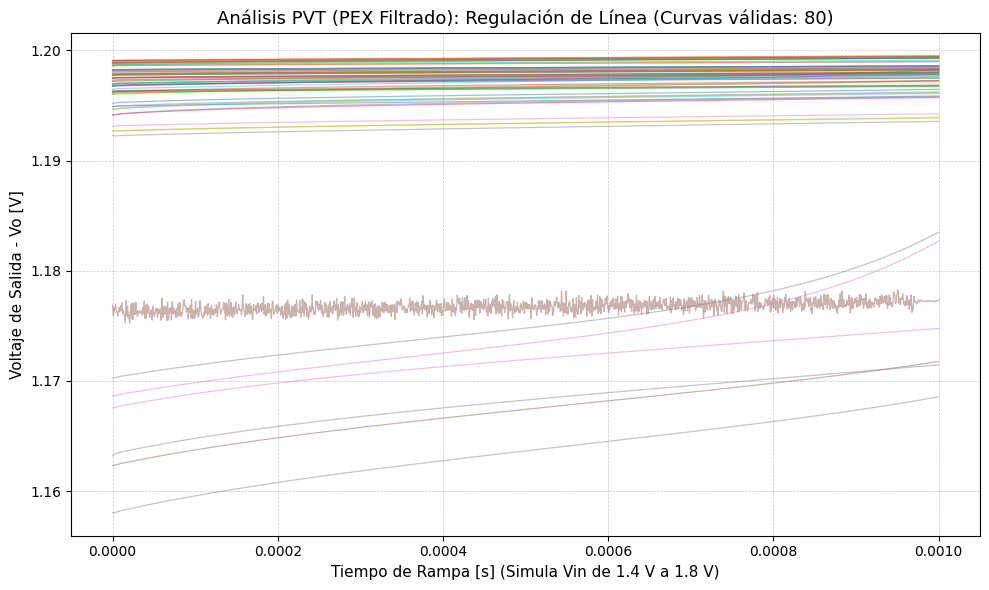

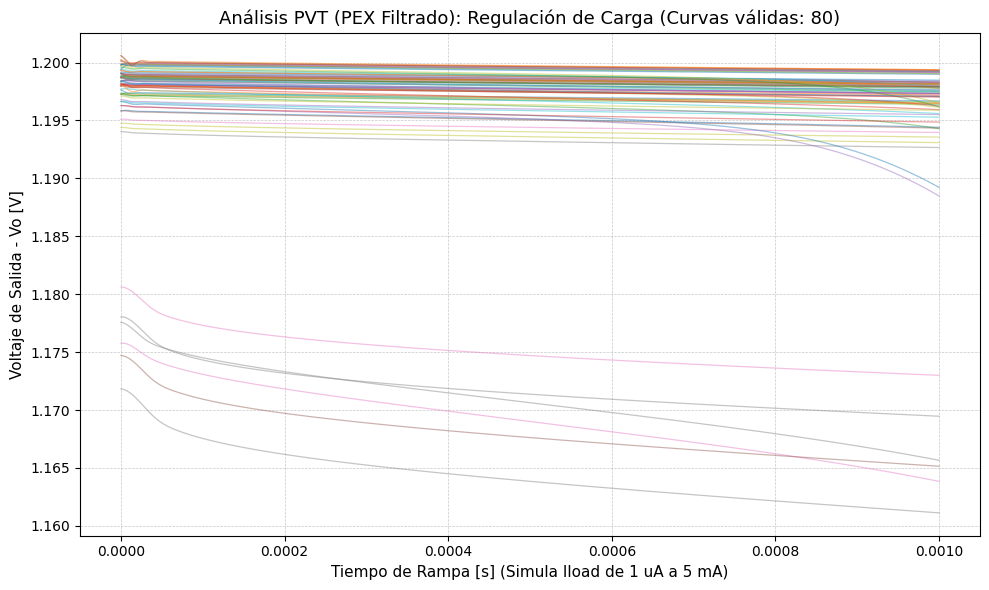

✅ Las 4 gráficas PEX filtradas fueron actualizadas y guardadas exitosamente.


In [1]:
# ==============================================================================
# ARCHIVO: Codigos_prueba.ipynb (Celda 1 - Filtrado y Graficación PEX)
# DESCRIPCIÓN:
#   Carga las curvas PEX desde 'resultados_simulacion/graficas_ldo_pex.pkl',
#   detecta y descarta automáticamente cualquier corner cuyo voltaje de salida
#   sea negativo (Vo < 0 V por falta de convergencia DC) y genera los 4 gráficos
#   del resto de esquinas PVT válidas.
# ==============================================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar los datos de gráficas PEX generados en la simulación
carpeta_destino = "resultados_simulacion"
ruta_graficas_pex = os.path.join(carpeta_destino, "graficas_ldo_pex.pkl")

with open(ruta_graficas_pex, "rb") as archivo:
    graficas_cargadas = pickle.load(archivo)

print(f"✅ Total de esquinas PVT cargadas desde '{ruta_graficas_pex}': {len(graficas_cargadas)}")

# 2. Lista manual opcional de corners a ignorar (además del filtro automático por Vo < 0 V)
corners_ignorados_manual = [
    # Puedes agregar nombres adicionales aquí si deseas ocultarlos manualmente:
    # "V_1_62_T_-40_sf",
    # "V_1_62_T_27_fs",
]

# 3. Detección automática de corners con problemas de convergencia (voltaje negativo Vo < 0 V)
corners_no_convergidos = set(corners_ignorados_manual)

for llave_pvt, datos_grafica in graficas_cargadas.items():
    # Revisamos las tres señales de voltaje de salida: transitorio, línea y carga
    for señal_vo in ["t_vo", "line_vo", "load_vo"]:
        if señal_vo in datos_grafica:
            arreglo_vo = np.real(datos_grafica[señal_vo])
            if len(arreglo_vo) > 0 and np.min(arreglo_vo) < 0.0:
                corners_no_convergidos.add(llave_pvt)
                print(
                    f"⚠️ Omitiendo corner por voltaje negativo ({señal_vo} min = {np.min(arreglo_vo):.4f} V): {llave_pvt}"
                )

# Crear diccionario filtrado únicamente con los corners que sí convergieron
graficas_filtradas = {
    llave: curvas
    for llave, curvas in graficas_cargadas.items()
    if llave not in corners_no_convergidos
}

print(f"📊 Esquinas válidas a graficar tras el filtrado: {len(graficas_filtradas)} de {len(graficas_cargadas)}\n")

# ==============================================================================
# 4. GENERACIÓN DE LAS 4 GRÁFICAS PEX DEL RESTO DE CORNERS
# ==============================================================================

# --- GRÁFICA 1: PSRR ---
plt.figure(figsize=(10, 6))
exitosas_psrr = 0
for llave, curvas in graficas_filtradas.items():
    if "frecuencia" in curvas and "psrr" in curvas:
        x = np.abs(curvas["frecuencia"])
        y = np.real(curvas["psrr"])
        min_len = min(len(x), len(y))
        plt.semilogx(x[:min_len], y[:min_len], linewidth=0.9, alpha=0.45, label=llave)
        exitosas_psrr += 1

plt.title(f"Análisis PVT (PEX Filtrado): PSRR del LDO (Curvas válidas: {exitosas_psrr})", fontsize=13)
plt.xlabel("Frecuencia [Hz]", fontsize=11)
plt.ylabel("PSRR [dB]", fontsize=11)
plt.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("psrr_pex.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRÁFICA 2: RESPUESTA TRANSITORIA (Overshoot y Undershoot) ---
plt.figure(figsize=(10, 6))
exitosas_tran = 0
for llave, curvas in graficas_filtradas.items():
    if "time" in curvas and "t_vo" in curvas:
        x = np.real(curvas["time"])
        y = np.real(curvas["t_vo"])
        min_len = min(len(x), len(y))
        plt.plot(x[:min_len], y[:min_len], linewidth=0.9, alpha=0.45, label=llave)
        exitosas_tran += 1

plt.title(f"Análisis PVT (PEX Filtrado): Respuesta Transitoria (Curvas válidas: {exitosas_tran})", fontsize=13)
plt.xlabel("Tiempo [s]", fontsize=11)
plt.ylabel("Voltaje de Salida - Vo [V]", fontsize=11)
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("tran_pex.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRÁFICA 3: REGULACIÓN DE LÍNEA (Rampa de Vin) ---
plt.figure(figsize=(10, 6))
exitosas_line = 0
for llave, curvas in graficas_filtradas.items():
    if "line_time" in curvas and "line_vo" in curvas:
        x = np.real(curvas["line_time"])
        y = np.real(curvas["line_vo"])
        min_len = min(len(x), len(y))
        plt.plot(x[:min_len], y[:min_len], linewidth=0.9, alpha=0.45, label=llave)
        exitosas_line += 1

plt.title(f"Análisis PVT (PEX Filtrado): Regulación de Línea (Curvas válidas: {exitosas_line})", fontsize=13)
plt.xlabel("Tiempo de Rampa [s] (Simula Vin de 1.4 V a 1.8 V)", fontsize=11)
plt.ylabel("Voltaje de Salida - Vo [V]", fontsize=11)
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("grafica_regulacion_linea_pex.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRÁFICA 4: REGULACIÓN DE CARGA (Rampa de Iload) ---
plt.figure(figsize=(10, 6))
exitosas_load = 0
for llave, curvas in graficas_filtradas.items():
    if "load_time" in curvas and "load_vo" in curvas:
        x = np.real(curvas["load_time"])
        y = np.real(curvas["load_vo"])
        min_len = min(len(x), len(y))
        plt.plot(x[:min_len], y[:min_len], linewidth=0.9, alpha=0.45, label=llave)
        exitosas_load += 1

plt.title(f"Análisis PVT (PEX Filtrado): Regulación de Carga (Curvas válidas: {exitosas_load})", fontsize=13)
plt.xlabel("Tiempo de Rampa [s] (Simula Iload de 1 uA a 5 mA)", fontsize=11)
plt.ylabel("Voltaje de Salida - Vo [V]", fontsize=11)
plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.savefig("grafica_regulacion_carga_pex.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Las 4 gráficas PEX filtradas fueron actualizadas y guardadas exitosamente.")


In [2]:
# ==============================================================================
# ARCHIVO: Codigos_prueba.ipynb (Celda 2 - Filtrado de Tabla Resumen PEX)
# DESCRIPCIÓN:
#   Carga los parámetros numéricos desde 'resultados_simulacion/parametros_ldo_pex.pkl',
#   elimina las esquinas no convergidas (con voltajes negativos) y actualiza
#   los archivos CSV ('225_Corners_LDO_PEX.csv' y 'Resumen_Peores_Casos_LDO_PEX.csv')
#   para que los valores mínimos y promedios no se vean distorsionados.
# ==============================================================================

import pandas as pd

ruta_parametros_pex = os.path.join(carpeta_destino, "parametros_ldo_pex.pkl")

with open(ruta_parametros_pex, "rb") as archivo:
    parametros_cargados = pickle.load(archivo)

# Filtrar el diccionario de parámetros quitando los corners con voltaje negativo
parametros_filtrados = {
    llave: metricas
    for llave, metricas in parametros_cargados.items()
    if llave not in corners_no_convergidos
}

df_resultados_filtrado = pd.DataFrame.from_dict(parametros_filtrados, orient="index")
df_resumen_filtrado = df_resultados_filtrado.agg(["min", "max", "mean"]).T

print("--- Resumen PVT (PEX Filtrado sin errores de convergencia) ---")
try:
    display(df_resumen_filtrado)
except NameError:
    print(df_resumen_filtrado)

# Guardar los CSV limpios
df_resultados_filtrado.to_csv("225_Corners_LDO_PEX.csv")
df_resumen_filtrado.to_csv("Resumen_Peores_Casos_LDO_PEX.csv")
print("\n✅ Tablas '225_Corners_LDO_PEX.csv' y 'Resumen_Peores_Casos_LDO_PEX.csv' actualizadas sin valores negativos.")


--- Resumen PVT (PEX Filtrado sin errores de convergencia) ---


,min,max,mean
temp,-40.000000,125.000000,38.300000
gananciapsrr_1,16.435650,110.323000,63.050176
gananciapsrr_1k,16.434910,83.800120,61.149067
gananciapsrr_10k,16.370800,64.039860,53.900533
gananciapsrr_1m,38.892320,63.998580,46.636262
voline_max,1.167910,1.199500,1.195864
at,0.000231,0.000437,0.000337
voline_min,1.158710,1.199150,1.194639
salida_line,1.163518,1.199327,1.195265
from,0.000150,0.000150,0.000150



✅ Tablas '225_Corners_LDO_PEX.csv' y 'Resumen_Peores_Casos_LDO_PEX.csv' actualizadas sin valores negativos.
